<a href="https://colab.research.google.com/github/divyadharshiniug/24ADI006L_24BAD023/blob/main/24BAD023_DL_EX_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name    : Divyadharshini U G
Roll No : 24BAD023
TensorFlow version: 2.21.0
--------------------------------------------------
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images shape : (60000, 28, 28)
Training labels shape : (60000,)
Testing images shape  : (10000, 28, 28)
Testing labels shape  : (10000,)
Data type of images   : uint8
Pixel value range     : min = 0 , max = 255
Number of classes     : 10
--------------------------------------------------
After normalization   : min = 0.0 , max = 1.0
Data type after       : float32
--------------------------------------------------
Flattened training shape : (60000, 784)
Flattened testing shape  : (10000, 784)
--------------------------------------------------
Input  (X) shape : (60000, 784)
Target (Y) shape : (60000, 784) (same as input)


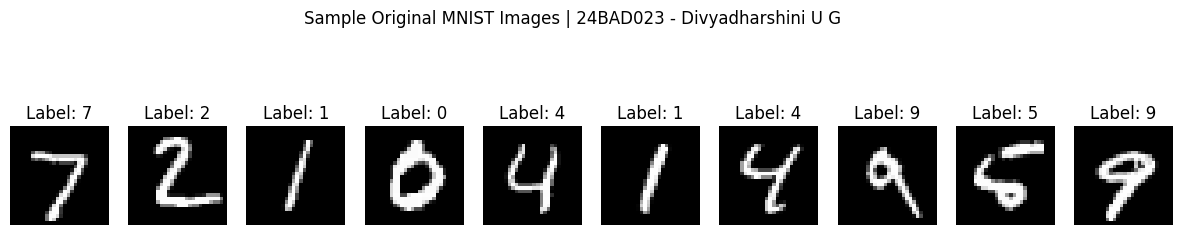

In [ ]:
# ============================================================
# EXPT 7 - Simple Autoencoder for Dimensionality Reduction
# PART A: DATASET PREPARATION
# Name    : Divyadharshini U G
# Roll No : 24BAD023
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

print("Name    : Divyadharshini U G")
print("Roll No : 24BAD023")
print("TensorFlow version:", tf.__version__)
print("-" * 50)

# 1. Load the MNIST dataset (already split into train and test)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. Explore the dataset
print("Training images shape :", x_train.shape)
print("Training labels shape :", y_train.shape)
print("Testing images shape  :", x_test.shape)
print("Testing labels shape  :", y_test.shape)
print("Data type of images   :", x_train.dtype)
print("Pixel value range     : min =", x_train.min(), ", max =", x_train.max())
print("Number of classes     :", len(np.unique(y_train)))
print("-" * 50)

# 3. Normalize pixel values to the range 0 to 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("After normalization   : min =", x_train.min(), ", max =", x_train.max())
print("Data type after       :", x_train.dtype)

# 4. Reshape 28x28 images into 784-dimensional vectors (Dense Autoencoder)
x_train_flat = x_train.reshape((len(x_train), 28 * 28))
x_test_flat = x_test.reshape((len(x_test), 28 * 28))
print("-" * 50)
print("Flattened training shape :", x_train_flat.shape)
print("Flattened testing shape  :", x_test_flat.shape)

# 5. For an autoencoder, the input is also the target output
print("-" * 50)
print("Input  (X) shape :", x_train_flat.shape)
print("Target (Y) shape :", x_train_flat.shape, "(same as input)")

# 6. Display a sample of the original images
n = 10
plt.figure(figsize=(15, 3))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Label: {y_test[i]}")
    plt.axis("off")
plt.suptitle("Sample Original MNIST Images | 24BAD023 - Divyadharshini U G", y=1.05)
plt.show()

Name    : Divyadharshini U G
Roll No : 24BAD023
--------------------------------------------------

========== AUTOENCODER SUMMARY ==========


Model: "autoencoder_24BAD023"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ latent_input (InputLayer)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,360 (411.56 KB)

 Trainable params: 105,360 (411.56 KB)

 Non-trainable params: 0 (0.00 B)

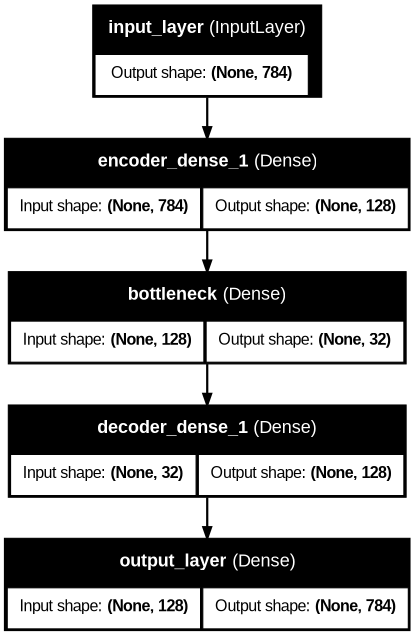

In [ ]:
# ============================================================
# EXPT 7 - Simple Autoencoder for Dimensionality Reduction
# PART B: IMPLEMENTING THE AUTOENCODER MODEL
# Name    : Divyadharshini U G
# Roll No : 24BAD023
# ============================================================

from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.utils import plot_model

print("Name    : Divyadharshini U G")
print("Roll No : 24BAD023")
print("-" * 50)

# Hyperparameters
input_dim = 784        # 28 x 28 flattened image
hidden_dim = 128       # intermediate encoder / decoder layer
latent_dim = 32        # bottleneck size (784 -> 32, about 24.5x compression)

# 1. Input layer
input_img = Input(shape=(input_dim,), name="input_layer")

# 2. Encoder: 784 -> 128 -> 32 (bottleneck)
encoded = Dense(hidden_dim, activation="relu", name="encoder_dense_1")(input_img)
bottleneck = Dense(latent_dim, activation="relu", name="bottleneck")(encoded)

# 3. Decoder: 32 -> 128 -> 784
decoded = Dense(hidden_dim, activation="relu", name="decoder_dense_1")(bottleneck)
output_img = Dense(input_dim, activation="sigmoid", name="output_layer")(decoded)

# 4. Complete Autoencoder (input -> reconstructed output)
autoencoder = Model(inputs=input_img, outputs=output_img, name="autoencoder_24BAD023")

# 5. Separate Encoder model (used later in Part D for latent features)
encoder = Model(inputs=input_img, outputs=bottleneck, name="encoder_24BAD023")

# 6. Separate Decoder model (used later in Part D for reconstruction)
latent_input = Input(shape=(latent_dim,), name="latent_input")
x = autoencoder.get_layer("decoder_dense_1")(latent_input)
x = autoencoder.get_layer("output_layer")(x)
decoder = Model(inputs=latent_input, outputs=x, name="decoder_24BAD023")

# 7. Compile: Adam optimizer + Mean Squared Error reconstruction loss
autoencoder.compile(optimizer="adam", loss="mse")

# 8. Display model summaries
print("\n========== AUTOENCODER SUMMARY ==========")
autoencoder.summary()

print("\n========== ENCODER SUMMARY ==========")
encoder.summary()

print("\n========== DECODER SUMMARY ==========")
decoder.summary()

# 9. Display model architecture diagram
plot_model(autoencoder, to_file="autoencoder_architecture.png",
           show_shapes=True, show_layer_names=True, dpi=80)
from IPython.display import Image, display
display(Image("autoencoder_architecture.png"))

Name    : Divyadharshini U G
Roll No : 24BAD023
--------------------------------------------------
Epoch 1/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0575 - val_loss: 0.0319
Epoch 2/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0252 - val_loss: 0.0201
Epoch 3/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0181 - val_loss: 0.0157
Epoch 4/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0149 - val_loss: 0.0137
Epoch 5/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0132 - val_loss: 0.0122
Epoch 6/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0122 - val_loss: 0.0114
Epoch 7/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 0.0115 - val_loss: 0.0109
Epoch 8/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0110 - val_loss: 0.0105
Epoch 9/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0107 - val_loss: 0.0102
Epoch 10/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0104 - val_loss: 0.0100
Epoch 11/50
235/235 ━━━━━━━━━━

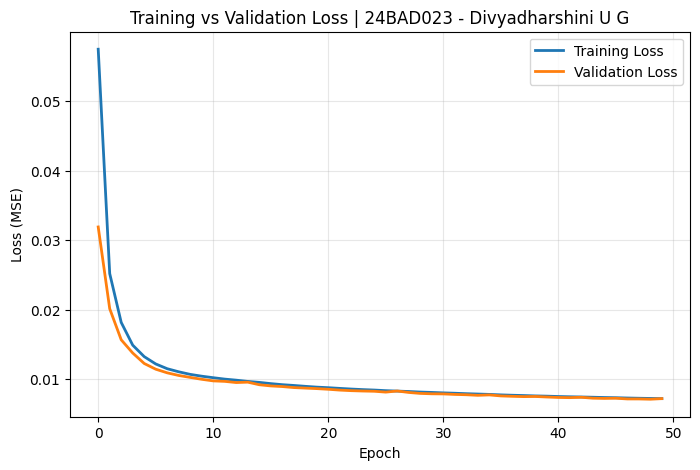

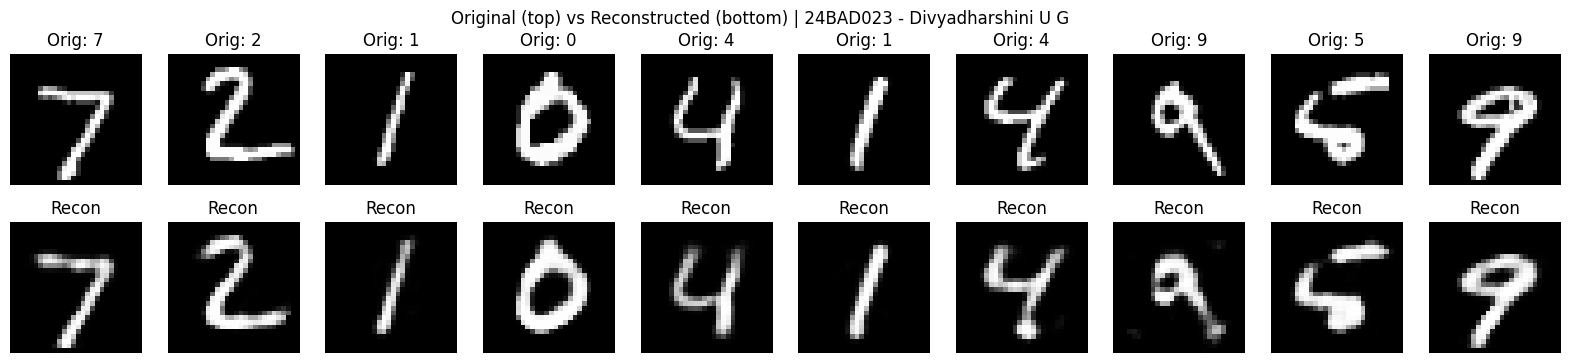

In [ ]:
# ============================================================
# EXPT 7 - Simple Autoencoder for Dimensionality Reduction
# PART C: MODEL TRAINING AND PERFORMANCE EVALUATION
# Name    : Divyadharshini U G
# Roll No : 24BAD023
# ============================================================

print("Name    : Divyadharshini U G")
print("Roll No : 24BAD023")
print("-" * 50)

# 1. Train the autoencoder (input = target = original images)
history = autoencoder.fit(
    x_train_flat, x_train_flat,
    epochs=50,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_flat, x_test_flat),
    verbose=1
)

# 2. Record training and validation loss
print("-" * 50)
print(f"Final Training Loss   : {history.history['loss'][-1]:.6f}")
print(f"Final Validation Loss : {history.history['val_loss'][-1]:.6f}")
print(f"Best Validation Loss  : {min(history.history['val_loss']):.6f} "
      f"(epoch {np.argmin(history.history['val_loss']) + 1})")

# 3. Evaluate on the test dataset
test_loss = autoencoder.evaluate(x_test_flat, x_test_flat, verbose=0)
print("-" * 50)
print(f"Test Loss (MSE) from evaluate() : {test_loss:.6f}")

# 4. Calculate reconstruction MSE manually
reconstructed = autoencoder.predict(x_test_flat, verbose=0)
mse_manual = np.mean(np.square(x_test_flat - reconstructed))
print(f"Reconstruction MSE (manual)     : {mse_manual:.6f}")
print(f"Reconstruction MSE per image    : {np.mean(np.square(x_test_flat - reconstructed), axis=1).mean():.6f}")

# 5. Plot training and validation loss vs epochs
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss", linewidth=2)
plt.plot(history.history["val_loss"], label="Validation Loss", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Training vs Validation Loss | 24BAD023 - Divyadharshini U G")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 6. Compare original images with reconstructed outputs
n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test_flat[i].reshape(28, 28), cmap="gray")
    plt.title(f"Orig: {y_test[i]}")
    plt.axis("off")
    # Reconstructed
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.title("Recon")
    plt.axis("off")
plt.suptitle("Original (top) vs Reconstructed (bottom) | 24BAD023 - Divyadharshini U G")
plt.show()

Name    : Divyadharshini U G
Roll No : 24BAD023
--------------------------------------------------
Original input shape     : (10000, 784)
Latent representation    : (10000, 32)
Dimensionality reduced   : 784 -> 32
Compression ratio        : 24.50x
Size reduction           : 95.92%
--------------------------------------------------
Sample latent vector (first test image):
[ 6.851  2.762  6.455 14.937  3.287 14.343  9.295  5.175  0.     6.451
  8.999 11.658  5.217 16.442 14.917  7.272  6.214  9.088 10.252  7.605
  7.095  7.07   4.232  5.736 11.037 11.434  5.417  4.832  9.171  6.829
  9.816 13.285]
--------------------------------------------------
Variance explained by 2 PCA components: [0.345 0.095]


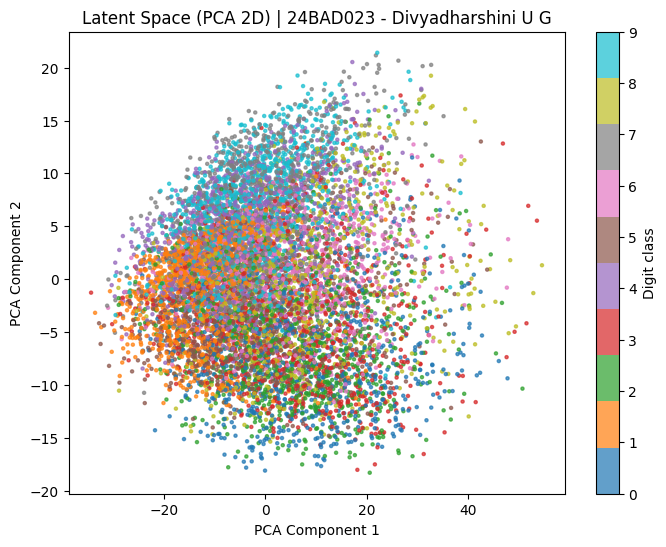

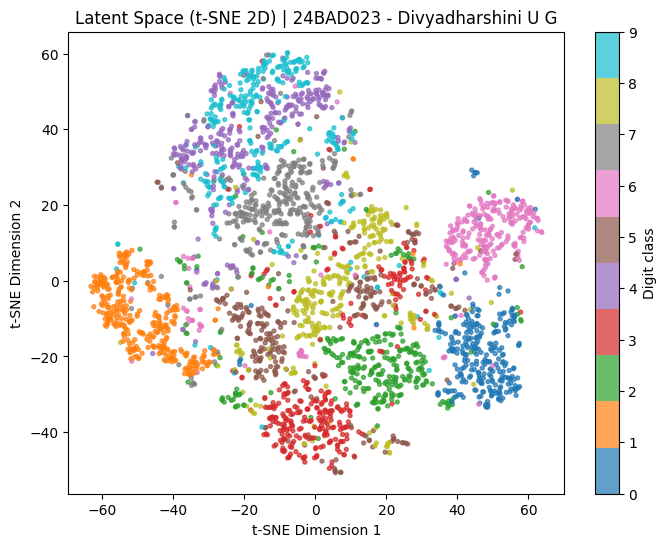

Decoder output matches autoencoder output: True


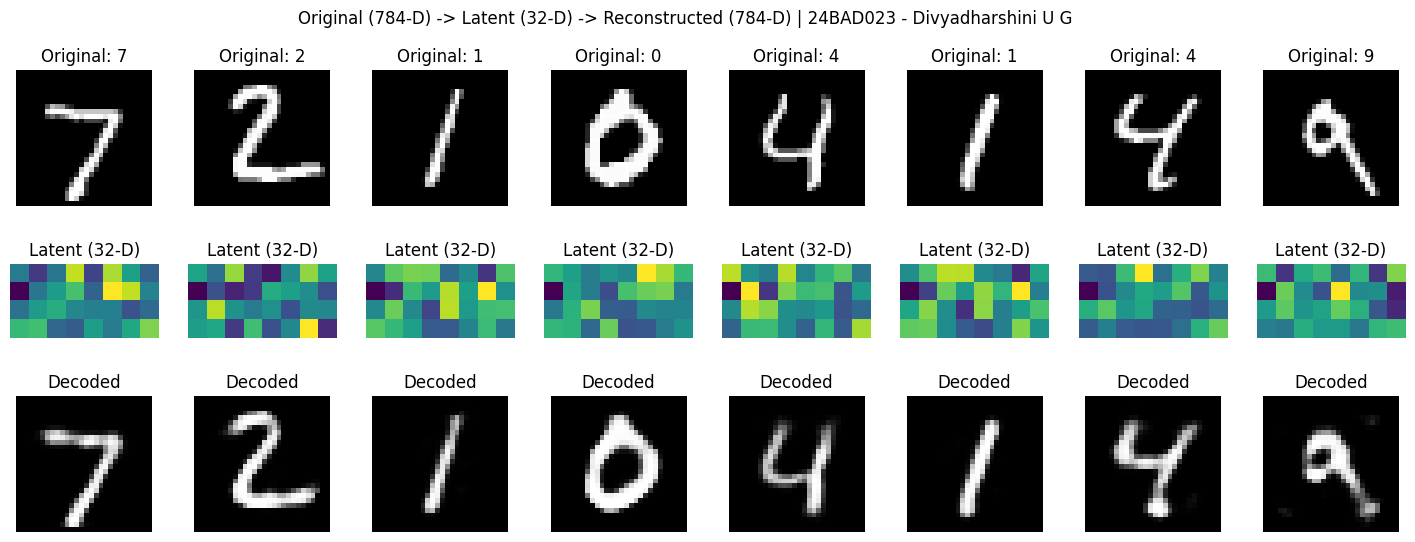

--------------------------------------------------
Average reconstruction MSE per digit class:
  Digit 0: 0.007498
  Digit 1: 0.002017
  Digit 2: 0.009840
  Digit 3: 0.007933
  Digit 4: 0.007569
  Digit 5: 0.008691
  Digit 6: 0.007654
  Digit 7: 0.005520
  Digit 8: 0.010312
  Digit 9: 0.005773


In [ ]:
# ============================================================
# EXPT 7 - Simple Autoencoder for Dimensionality Reduction
# PART D: DIMENSIONALITY REDUCTION, FEATURE VISUALIZATION
# Name    : Divyadharshini U G
# Roll No : 24BAD023
# ============================================================

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("Name    : Divyadharshini U G")
print("Roll No : 24BAD023")
print("-" * 50)

# 1. Extract latent-space representations using the trained Encoder
latent_test = encoder.predict(x_test_flat, verbose=0)

# 2. Compare dimensions of original data vs compressed representation
print("Original input shape     :", x_test_flat.shape)
print("Latent representation    :", latent_test.shape)
print(f"Dimensionality reduced   : {x_test_flat.shape[1]} -> {latent_test.shape[1]}")
print(f"Compression ratio        : {x_test_flat.shape[1] / latent_test.shape[1]:.2f}x")
print(f"Size reduction           : {(1 - latent_test.shape[1] / x_test_flat.shape[1]) * 100:.2f}%")
print("-" * 50)
print("Sample latent vector (first test image):")
print(np.round(latent_test[0], 3))
print("-" * 50)

# 3. Visualize latent representations in 2D using PCA
pca = PCA(n_components=2)
latent_pca = pca.fit_transform(latent_test)
print("Variance explained by 2 PCA components:",
      np.round(pca.explained_variance_ratio_, 3))

plt.figure(figsize=(8, 6))
scatter = plt.scatter(latent_pca[:, 0], latent_pca[:, 1],
                      c=y_test, cmap="tab10", s=5, alpha=0.7)
plt.colorbar(scatter, label="Digit class")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Latent Space (PCA 2D) | 24BAD023 - Divyadharshini U G")
plt.show()

# 4. Visualize latent representations in 2D using t-SNE (first 3000 samples for speed)
n_tsne = 3000
latent_tsne = TSNE(n_components=2, random_state=42, init="pca").fit_transform(latent_test[:n_tsne])

plt.figure(figsize=(8, 6))
scatter = plt.scatter(latent_tsne[:, 0], latent_tsne[:, 1],
                      c=y_test[:n_tsne], cmap="tab10", s=8, alpha=0.7)
plt.colorbar(scatter, label="Digit class")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("Latent Space (t-SNE 2D) | 24BAD023 - Divyadharshini U G")
plt.show()

# 5. Reconstruct selected test samples using the Decoder
decoded_imgs = decoder.predict(latent_test, verbose=0)

# Confirm decoder output matches the full autoencoder output
print("Decoder output matches autoencoder output:",
      np.allclose(decoded_imgs, autoencoder.predict(x_test_flat, verbose=0), atol=1e-5))

# 6. Compare original, latent code and reconstruction for selected samples
n = 8
plt.figure(figsize=(18, 6))
for i in range(n):
    # Original (784 dims)
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test_flat[i].reshape(28, 28), cmap="gray")
    plt.title(f"Original: {y_test[i]}")
    plt.axis("off")
    # Latent code (32 dims shown as 4x8 grid)
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(latent_test[i].reshape(4, 8), cmap="viridis")
    plt.title("Latent (32-D)")
    plt.axis("off")
    # Decoder reconstruction
    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
    plt.title("Decoded")
    plt.axis("off")
plt.suptitle("Original (784-D) -> Latent (32-D) -> Reconstructed (784-D) | 24BAD023 - Divyadharshini U G")
plt.show()

# 7. Per-digit reconstruction error (helps the observations)
errors = np.mean(np.square(x_test_flat - decoded_imgs), axis=1)
print("-" * 50)
print("Average reconstruction MSE per digit class:")
for d in range(10):
    print(f"  Digit {d}: {errors[y_test == d].mean():.6f}")